In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

from aspire.utils import gaussian_window, grid_2d, randn, trange
import tqdm
from overcrowding_utils import estimate_mean_naive, estimate_covar_naive, estimate_mean_ctfless, estimate_covar_ctfless, conv_diag, make_p_eff, estimate_psd
from utils_cwf_fast_batch import get_clean_mean_batch, get_clean_covar_batch, get_noise_var_batch
from scipy.sparse.linalg import LinearOperator, gmres
from scipy.signal import fftconvolve, oaconvolve
from aspire.source.micrograph import MicrographSimulation
from aspire.volume import Volume
from aspire.utils import Rotation, logging
from aspire.source import ArrayImageSource, Simulation
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RegularGridInterpolator
from aspire.noise import WhiteNoiseAdder, CustomNoiseAdder
from aspire.operators import  RadialCTFFilter
from itertools import permutations
from scipy.sparse import coo_matrix
import time

logging.setConsoleLoggingLevel("WARNING")

downsample_size = 48
psd_size = 96
pad_width = (psd_size - downsample_size)//2
dtype = np.float64


A = 1 * np.eye(psd_size**2, psd_size**2).reshape(psd_size, psd_size, psd_size, psd_size)
A = np.fft.fftshift(A, axes=(0, 1))
A = np.fft.fft2(A, axes=(0, 1))
A = np.fft.ifftshift(A, axes=(0, 1))
A = np.fft.fftshift(A, axes=(2, 3))
A = np.fft.fft2(A, axes=(2, 3))
A = np.fft.ifftshift(A, axes=(2, 3))

tups = []
for i in range(psd_size**2):
    tups.append((i, np.where(A.reshape(psd_size**2, psd_size**2)[i] > 1)[0][0]))

rows, cols = zip(*tups)
noise_mat = coo_matrix(
    (np.ones(psd_size**2), (rows, cols)),
    shape=(psd_size**2, psd_size**2)
)

In [2]:
vol = Volume.load('/tigress/CRYOEM/singerlab/az8940/10028/Refine3D/job003/run_class001.mrc').downsample(downsample_size).astype(np.float64).asnumpy()[0]

In [3]:
micrograph_size = downsample_size * 11 #psd_size * 10

In [4]:
rng = np.random.default_rng(seed=1234)

100.97899034153141
10248.24449865578


100%|██████████| 24/24 [00:27<00:00,  1.15s/it]


Time took for gmres: 0.7626111308733622 min
0.8529059022109258 13.53118799602077
100.791325349202
10194.415158230211


100%|██████████| 24/24 [00:27<00:00,  1.16s/it]


Time took for gmres: 0.7691927035649617 min
0.7483382732426918 9.691752893198954
100.1974079639369
10074.623591284748


100%|██████████| 24/24 [00:28<00:00,  1.20s/it]


Time took for gmres: 0.7756543199221293 min
0.7021477170791427 6.9915275101664776


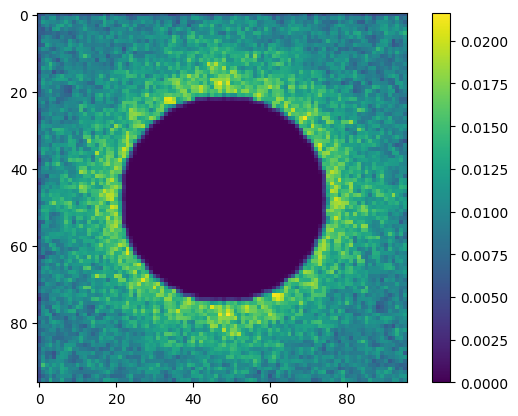

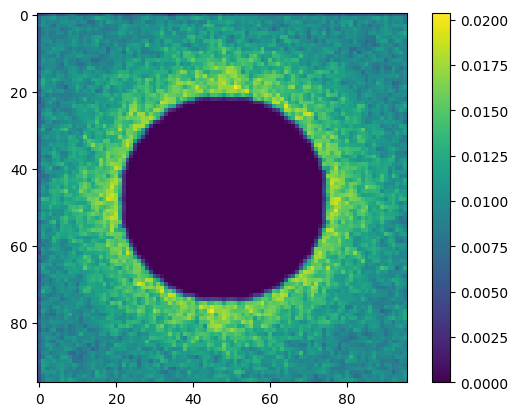

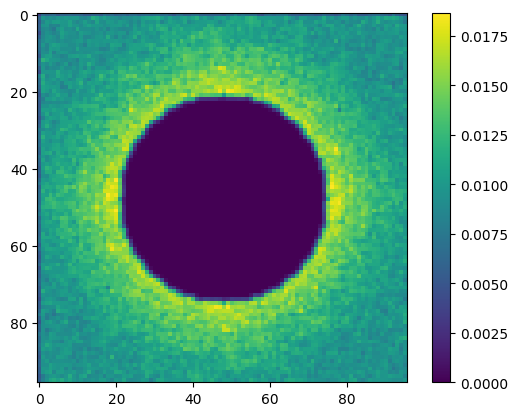

<Figure size 640x480 with 0 Axes>

In [5]:
nums_micrographs = [400, 800, 1600]
covar_errs = []
clean_covar_errs = []
mean_errs = []
clean_mean_errs = []
for num_micrographs in nums_micrographs:
    particles_per_micrograph = rng.integers(80, 121, num_micrographs)
    total_particles = np.sum(particles_per_micrograph)
    angles = Rotation.generate_random_rotations(total_particles, seed = 1234).angles
    alpha_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1))
    beta_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1) * (particles_per_micrograph - 2))
    alpha = alpha_numerator / total_particles
    beta = beta_numerator / total_particles
    print(alpha)
    print(beta)
    pixel_size = 1.34 * 360 / downsample_size
    split_angles = np.split(angles, np.cumsum(particles_per_micrograph)[:-1])
    micro_srcs = []
    voltage = 300  # Voltage (in KV)
    defocus_min = 1e4  # Minimum defocus value (in angstroms)
    defocus_max = 4e4  # Maximum defocus value (in angstroms)
    defocus_ct = num_micrographs
    
    # Create filters. This is a list of CTFs. Each element corresponds to a UNIQUE CTF
    h_ctf = [
        RadialCTFFilter(voltage, defocus=d, Cs=2.0, alpha=0.1)
        for d in np.linspace(defocus_min, defocus_max, defocus_ct)
    ]
    h_idx = [i for i, count in enumerate(particles_per_micrograph) for _ in range(count)]
    
    ctfless_uncrowded_src = Simulation(
        L=downsample_size,
        n=total_particles,
        vols=Volume(vol),
        amplitudes=downsample_size,
        dtype=dtype,
        offsets = 0,
        pixel_size = pixel_size,
        angles = angles
    )
    
    clean_uncrowded_src = Simulation(
        L=downsample_size,
        n=total_particles,
        vols=Volume(vol),
        amplitudes=downsample_size,
        dtype=dtype,
        offsets = 0,
        filter_indices=h_idx,
        unique_filters=h_ctf,
        pixel_size = pixel_size,
        angles = angles
    )
    noise_var = get_noise_var_batch(clean_uncrowded_src, 1/4, 5000)

    for i in range(num_micrographs):
        micro_srcs.append(MicrographSimulation(
                micrograph_size = micrograph_size,
                micrograph_count = 1,
                particles_per_micrograph=particles_per_micrograph[i],
                particle_amplitudes=psd_size,
                projection_angles = split_angles[i], 
                ctf_filters = [h_ctf[i]],
                volume=Volume(np.pad(vol, (pad_width,pad_width))),
                interparticle_distance = 9 * downsample_size / 16,
                boundary = psd_size//2,
                pixel_size = pixel_size,
                seed = 1234*i,
                noise_adder = WhiteNoiseAdder(noise_var, seed = 1234*i),
        )
                         )

    img_array = []
    for i in tqdm.tqdm(range(num_micrographs)):
        micrograph = micro_srcs[i].images[0].asnumpy()[0]
        for center in micro_srcs[i].centers[0]:
            x, y = center
            if x - psd_size//2 >= 0 and x+psd_size//2 < micrograph_size and y - psd_size//2 >= 0 and y + psd_size//2 < micrograph_size:
                img_array.append(micrograph[x-psd_size//2:x+psd_size//2, y-psd_size//2:y+psd_size//2])
    img_array = np.array(img_array)
    crowded_src = ArrayImageSource(img_array, pixel_size = pixel_size)
    crowded_src.unique_filters = h_ctf
    crowded_src.filter_indices = h_idx
    center_offsets = rng.random((int(total_particles), 2)) - 0.5
    split_offsets = np.split(center_offsets, np.cumsum(particles_per_micrograph)[:-1])
    centers = [micro_srcs[i].centers[0].astype(np.float64) + split_offsets[i] for i in range(num_micrographs)]
    observed_covar = estimate_covar_naive(crowded_src, noise_mat, noise_var * np.ones((len(crowded_src.unique_filters), psd_size, psd_size))).reshape(psd_size,psd_size,psd_size,psd_size)[(slice(pad_width, -pad_width),) * 4]
    clean_mean = estimate_mean_ctfless(ctfless_uncrowded_src)
    clean_covar = estimate_covar_ctfless(ctfless_uncrowded_src).reshape(downsample_size,downsample_size,downsample_size,downsample_size)
    
    raw_distances = []
    for i in range(num_micrographs):
        comp = centers[i][None, :, :] - centers[i][:, None, :]
        to_add = comp[~np.eye(len(centers[i]), dtype=bool)] / downsample_size
        to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)))]
        raw_distances.append(to_add)
    raw_distances = np.concatenate(raw_distances)
    
    
    raw_triples = []
    for m in range(num_micrographs):
        pts = centers[m]
        N = len(pts)
        for i in range(N):
            V = pts - pts[i]
            V = V[np.linalg.norm(V, axis = 1) > 1e-12]
    
            V1 = np.broadcast_to(V[:, None, :], (N-1, N-1, 2))
            V2 = np.broadcast_to(V[None, :, :], (N-1, N-1, 2))
            
            pair_tensor = np.concatenate((V1, V2), axis=-1)
            pair_mask = ~np.eye(len(V), dtype=bool)
            to_add = pair_tensor[pair_mask] / downsample_size
            to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)) & (np.abs(to_add[:, 2]) <= np.sqrt(2)) & (np.abs(to_add[:, 3]) <= np.sqrt(2)))]
            raw_triples.append(to_add)
    raw_triples = np.concatenate(raw_triples, axis=0)
    
    Nu = 1024
    u_edges = np.linspace(-np.sqrt(2), np.sqrt(2) , Nu+1)
    H, edges = np.histogramdd(
        raw_distances,
        bins=[u_edges, u_edges],
        density=True
    ) 
    cut_scaling = len(raw_distances) / alpha_numerator
    m_mean = 4
    Hs = gaussian_filter(
        H,
        sigma=[1,1],
        mode=['nearest','nearest']
    )
    uc  = u_edges[:-1]
    log_interp = RegularGridInterpolator(
        (uc, uc),
        Hs * cut_scaling,
        bounds_error=False,
        fill_value = 0,
        method='linear'
    )   
    g = np.linspace(-1, 1, 2 * m_mean * downsample_size, endpoint = False) + 1e-8
    X1, X2 = np.meshgrid(
        g, g,
        indexing='ij'
    )
    pts = np.stack([
        X1.ravel(),
        X2.ravel()
    ], axis=1)
    vals = log_interp(pts).reshape(2 * m_mean * downsample_size, 2 * m_mean * downsample_size)
    eval_f_binning_hi = vals
    p_eff = make_p_eff(eval_f_binning_hi, downsample_size, m_mean)
    
    
    plt.imshow(p_eff)
    plt.colorbar()
    plt.figure()
    
    observed_mean = estimate_mean_naive(crowded_src)[(slice(pad_width, -pad_width),) * 2]
    
    mean_coords = np.arange(downsample_size) - downsample_size // 2
    X, Y = np.meshgrid(mean_coords, mean_coords, indexing="ij")
    
    # Can enforce compact support
    mean_indices = np.where(np.linalg.norm(np.array([X, Y]), axis = 0, ord =np.inf) <= downsample_size//2)
    
    mean_len = len(mean_indices[0])
    
    def matvec_mean_binning(v):
        v_ = np.zeros((downsample_size, downsample_size), dtype = np.complex128)
        v_[mean_indices] = v.flatten()
        
        term_hi = alpha * fftconvolve(p_eff, v_, mode = "full")[downsample_size:-downsample_size+1,downsample_size:-downsample_size+1] / (downsample_size)**2
        return (v_ + term_hi)[mean_indices]
        
    mean_A_binning = LinearOperator(
        shape=(mean_len, mean_len),
        matvec=matvec_mean_binning,
        dtype=np.float64,
    )
    
    remean_binning = np.zeros((downsample_size, downsample_size), dtype = np.complex128)
    soln_binning, info = gmres(mean_A_binning, observed_mean[mean_indices], rtol = 1e-6)
    remean_binning[mean_indices] = soln_binning
    clean_mean_err = np.linalg.norm(remean_binning.real - clean_mean) / np.linalg.norm(clean_mean) * 100
    # COVAR
    
    mean_diff_binning = observed_mean - remean_binning
    term2_binning = (mean_diff_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)).reshape(downsample_size, downsample_size, downsample_size, downsample_size)
    term3_binning = (remean_binning.reshape(-1, 1) @ mean_diff_binning.reshape(1, -1)).reshape(downsample_size, downsample_size, downsample_size, downsample_size)
    
    diag_p_binning_hi = np.diag(p_eff.ravel()).reshape(2*downsample_size, 2*downsample_size, 2*downsample_size, 2*downsample_size)
    
    Nu = 160 #512#256#128
    
    u_edges = np.linspace(-np.sqrt(2), np.sqrt(2) , Nu+1)
    
    H, _ = np.histogramdd(
        raw_triples,
        bins=[u_edges, u_edges, u_edges, u_edges],
        density=True
    )
    
    cut_scaling = len(raw_triples) / beta_numerator
    H = gaussian_filter(H, sigma=0.75, axes=(0, 1), mode='nearest')
    H = gaussian_filter(H, sigma=0.75, axes=(2, 3), mode='nearest') * cut_scaling
    uc = 0.5 * (u_edges[:-1] + u_edges[1:])
    log_interp = RegularGridInterpolator(
        (uc, uc, uc, uc),
        H,
        bounds_error=False,
        fill_value = 0,
        method='linear'
    )
    n = 2 * downsample_size
    g = np.linspace(-1, 1, n, endpoint=False) + 1e-8
    c_eff = np.empty((n, n, n, n), dtype=np.float64)
    chunk = 4 if downsample_size <= 64 else 1
    for i in tqdm.tqdm(range(0, n, chunk)):
        gi = g[i:i+chunk]
        m = len(gi)
    
        pts = np.empty((m * n**3, 4), dtype=np.float64)
    
        pts[:, 0] = np.repeat(gi, n**3)
        pts[:, 1] = np.tile(np.repeat(g, n**2), m)
        pts[:, 2] = np.tile(np.repeat(g, n), m * n)
        pts[:, 3] = np.tile(g, m * n**2)
    
        c_eff[i:i+m] = log_interp(pts).reshape(m, n, n, n)
    del log_interp 
    del pts
    del H
    
    tmp = oaconvolve(
        c_eff,
        remean_binning[:, :, None, None],
        mode="valid",
        axes=(0, 1),
    )[1:, 1:, :, :]
    
    term5_binning_hi = oaconvolve(
        tmp,
        remean_binning[None, None, :, :],
        mode="valid",
        axes=(2, 3),
    )[:, :, 1:, 1:]
    
    coords = np.arange(downsample_size) - downsample_size // 2
    X, Y, Z, ZZ = np.meshgrid(coords, coords, coords, coords, indexing="ij")
    indices = np.where(np.linalg.norm(np.array([X, Y, Z, ZZ]), axis = 0, ord = np.inf) <= downsample_size//2)
    
    def matvec_covar_binning(v):
        X = np.zeros((downsample_size, downsample_size, downsample_size, downsample_size), dtype=v.dtype)
    
        X[indices] = v.flatten()
    
        cov_hi = X # we will just use an effective diag_p_binning_hi instead of explicitly repeating
    
        term4_hi = conv_diag(cov_hi, p_eff)
    
        term4_hi *= alpha / downsample_size**2
        return v + term4_hi[indices] 
        
    A_covar_binning = LinearOperator(
        shape=(len(indices[0]), len(indices[0])),
        matvec=matvec_covar_binning,
        dtype=np.float64,
    )
    
    t0 = time.time()
    soln_binning, info = gmres(A_covar_binning, (observed_covar - (term2_binning + term3_binning  + \
                                                                                   beta * term5_binning_hi / (downsample_size)**4))[indices], rtol = 1e-6)
    print(f'Time took for gmres: {(time.time() - t0) / 60} min')
    recovar_binning = np.zeros((downsample_size, downsample_size, downsample_size, downsample_size), dtype=soln_binning.dtype)
    
    recovar_binning[indices] = soln_binning.flatten()
    est_uncrowded_outer_product = remean_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)
    
    crowded_outer_product = observed_mean.reshape(-1, 1) @ observed_mean.reshape(1, -1)
    clean_outer_product = (clean_mean.reshape(-1, 1) @ clean_mean.reshape(1, -1)).reshape(clean_covar.shape)
    clean_covar_err = np.linalg.norm(recovar_binning.reshape(clean_covar.shape) - clean_covar - (est_uncrowded_outer_product.reshape(clean_covar.shape) - clean_outer_product)) / np.linalg.norm(clean_covar - clean_outer_product.reshape(clean_covar.shape)) * 100

    clean_mean_errs.append(clean_mean_err)

    clean_covar_errs.append(clean_covar_err)
    print(clean_mean_err, clean_covar_err)

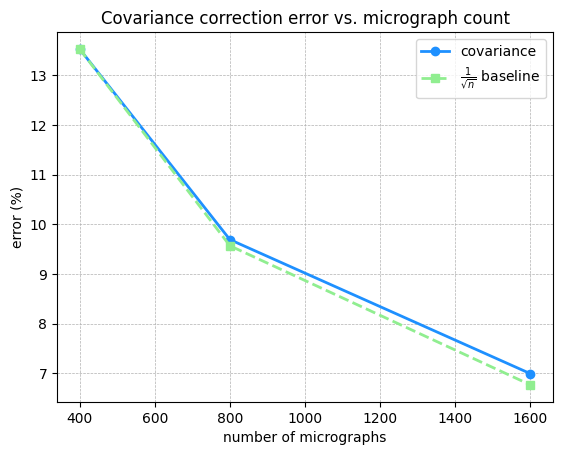

In [6]:
plt.plot(nums_micrographs, clean_covar_errs, "-o",lw=2.0,c="dodgerblue", label="covariance")
plt.plot(nums_micrographs, clean_covar_errs[0] * np.sqrt(nums_micrographs[0])/np.sqrt(nums_micrographs), "--s",lw=2.0,c="lightgreen", label="$\\frac{1}{\\sqrt{n}}$ baseline")

plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Covariance correction error vs. micrograph count")
plt.ylabel("error (%)")
plt.xlabel("number of micrographs")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res5/cov_vs_n.pdf", bbox_inches = "tight")

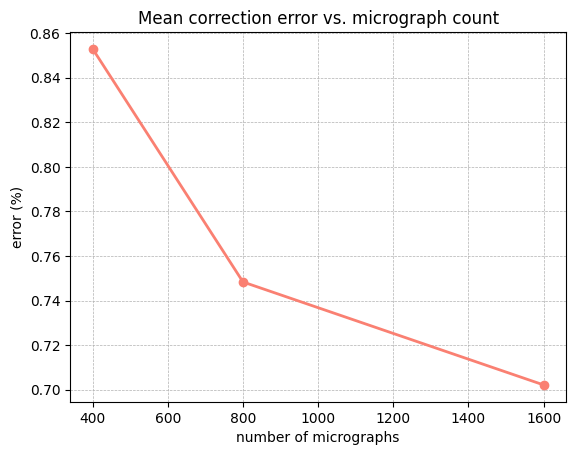

In [7]:
plt.plot(nums_micrographs, clean_mean_errs, "-o",lw=2.0, c="salmon", label = "mean")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Mean correction error vs. micrograph count")
plt.ylabel("error (%)")
plt.xlabel("number of micrographs")
plt.savefig("final_overcrowding_paper_figs/res5/mean_vs_n.pdf", bbox_inches = "tight")

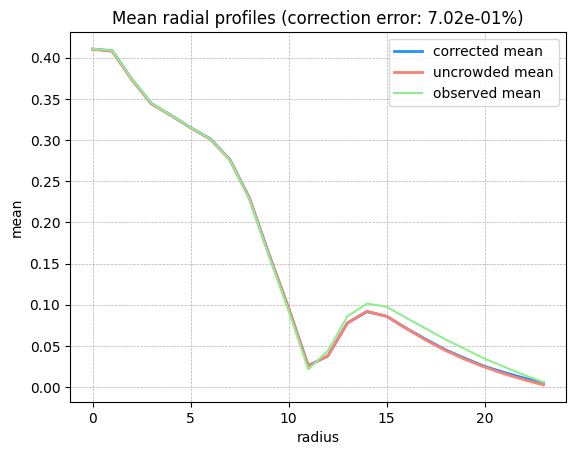

In [8]:
plt.plot(np.abs(remean_binning[downsample_size//2, downsample_size//2:]), lw=2.0,label = "corrected mean", color="dodgerblue")
plt.plot(np.abs(clean_mean[downsample_size//2, downsample_size//2:]), lw=2.0, label = "uncrowded mean", color="salmon")
plt.plot(np.abs(observed_mean[downsample_size//2, downsample_size//2:]), label = "observed mean", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {clean_mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res5/means.pdf",bbox_inches = "tight")

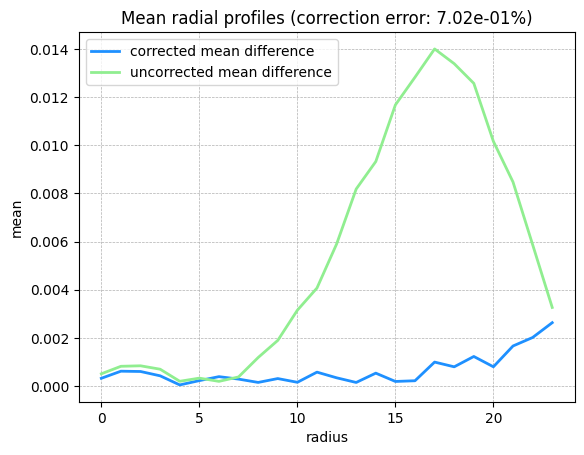

In [9]:
plt.plot(np.abs((remean_binning - clean_mean)[downsample_size//2, downsample_size//2:]), lw=2.0,label = "corrected mean difference", color="dodgerblue")
plt.plot(np.abs((observed_mean - clean_mean)[downsample_size//2, downsample_size//2:]), lw=2.0, label = "uncorrected mean difference", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {clean_mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res5/mean_diff.pdf",bbox_inches = "tight")

In [10]:
def save_image(img, fname, cmap="gray"):
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img, cmap=cmap)
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    fig.savefig(fname, format="pdf", bbox_inches="tight", pad_inches=0)
    plt.close(fig)

micrograph = micro_srcs[0].images[0].asnumpy()[0]
save_image(micrograph, "final_overcrowding_paper_figs/res5/micrograph.pdf")

particles = crowded_src.images[:2].asnumpy()[:,pad_width:-pad_width,pad_width:-pad_width]
save_image(particles[0], "final_overcrowding_paper_figs/res5/particle_1.pdf")
save_image(particles[1], "final_overcrowding_paper_figs/res5/particle_2.pdf")